In [2]:
%pip install xgboost --timeout 120 --retries 10

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import xgboost as xgb
import pandas as pd
import numpy as np
import sklearn

print("XGBoost :", xgb.__version__)
print("Pandas  :", pd.__version__)
print("NumPy   :", np.__version__)
print("Sklearn :", sklearn.__version__)

XGBoost : 3.4.1
Pandas  : 3.0.3
NumPy   : 2.4.6
Sklearn : 1.9.1


<H2>1. IMPORT LIBARY</H2>

In [4]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


<H2>2. Memuat Dataset</H2>

In [5]:
# Unggah file CSV ke folder kerja notebook, atau ubah path sesuai lokasi file.
DATA_PATH = "kolkata_weather_jan_june_2026.csv"
df = pd.read_csv(DATA_PATH)

print("Ukuran dataset:", df.shape)
display(df.head())


Ukuran dataset: (1827, 17)


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639


In [6]:
print("Informasi struktur data:")
df.info()


Informasi struktur data:
<class 'pandas.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   time                         1827 non-null   str    
 1   weather_code                 1827 non-null   int64  
 2   temperature_2m_mean          1827 non-null   float64
 3   temperature_2m_max           1827 non-null   float64
 4   temperature_2m_min           1827 non-null   float64
 5   precipitation_sum            1827 non-null   float64
 6   rain_sum                     1827 non-null   float64
 7   precipitation_hours          1827 non-null   float64
 8   wind_speed_10m_max           1827 non-null   float64
 9   wind_gusts_10m_max           1827 non-null   float64
 10  wind_direction_10m_dominant  1827 non-null   int64  
 11  sunrise                      1827 non-null   str    
 12  sunset                       1827 non-null   str    
 13  suns

In [7]:
display(df.describe(include="all").T)
print("\nRentang tanggal:", df["time"].min(), "sampai", df["time"].max())
print("\nJumlah kelas target:")
display(df["weather_code"].value_counts().sort_index().rename_axis("weather_code").to_frame("jumlah"))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
time,1827,1827,2021-06-30,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_code,1827.0,NaN,NaN,NaN,34.143952,28.997216,0.0,3.0,51.0,63.0,65.0
temperature_2m_mean,1827.0,NaN,NaN,NaN,26.26486,4.05022,15.0,23.4,27.4,29.1,35.2
temperature_2m_max,1827.0,NaN,NaN,NaN,31.099234,3.924558,19.6,28.7,31.3,33.3,43.9
temperature_2m_min,1827.0,NaN,NaN,NaN,22.477066,4.847343,10.2,18.6,24.6,26.2,30.6
precipitation_sum,1827.0,NaN,NaN,NaN,5.429119,9.550693,0.0,0.0,0.4,7.35,80.5
rain_sum,1827.0,NaN,NaN,NaN,5.429119,9.550693,0.0,0.0,0.4,7.35,80.5
precipitation_hours,1827.0,NaN,NaN,NaN,4.952928,6.275264,0.0,0.0,2.0,9.0,24.0
wind_speed_10m_max,1827.0,NaN,NaN,NaN,13.782157,5.106847,4.5,10.0,12.6,16.6,44.0
wind_gusts_10m_max,1827.0,NaN,NaN,NaN,30.756596,9.081119,11.5,24.1,29.5,36.0,83.9



Rentang tanggal: 2021-06-30 sampai 2026-06-30

Jumlah kelas target:


,jumlah
weather_code,
0,228
1,94
2,78
3,406
51,167
53,108
55,40
61,145
63,419


<h2>3. Eksplorasi Data (EDA)</h2>

In [8]:
# Nilai kosong per kolom
missing = pd.DataFrame({
    "Jumlah Missing": df.isna().sum(),
    "Persentase (%)": (df.isna().mean() * 100).round(2)
})
display(missing)


,Jumlah Missing,Persentase (%)
time,0,0.0
weather_code,0,0.0
temperature_2m_mean,0,0.0
temperature_2m_max,0,0.0
temperature_2m_min,0,0.0
precipitation_sum,0,0.0
rain_sum,0,0.0
precipitation_hours,0,0.0
wind_speed_10m_max,0,0.0
wind_gusts_10m_max,0,0.0


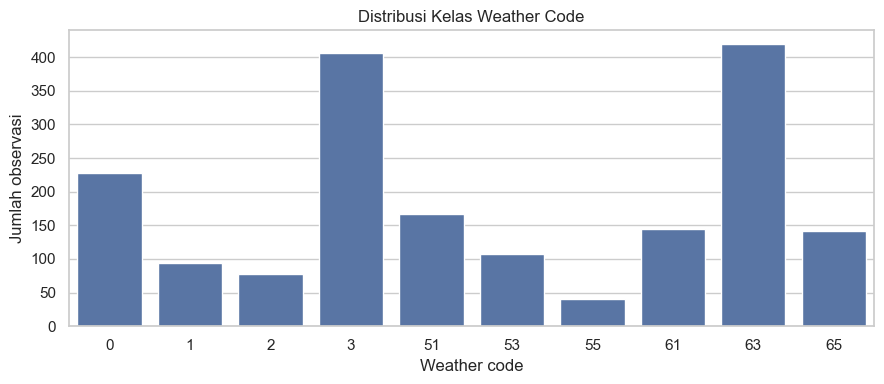

In [9]:
# Distribusi target
plt.figure(figsize=(9, 4))
sns.countplot(data=df, x="weather_code", order=sorted(df["weather_code"].unique()))
plt.title("Distribusi Kelas Weather Code")
plt.xlabel("Weather code")
plt.ylabel("Jumlah observasi")
plt.tight_layout()
plt.show()

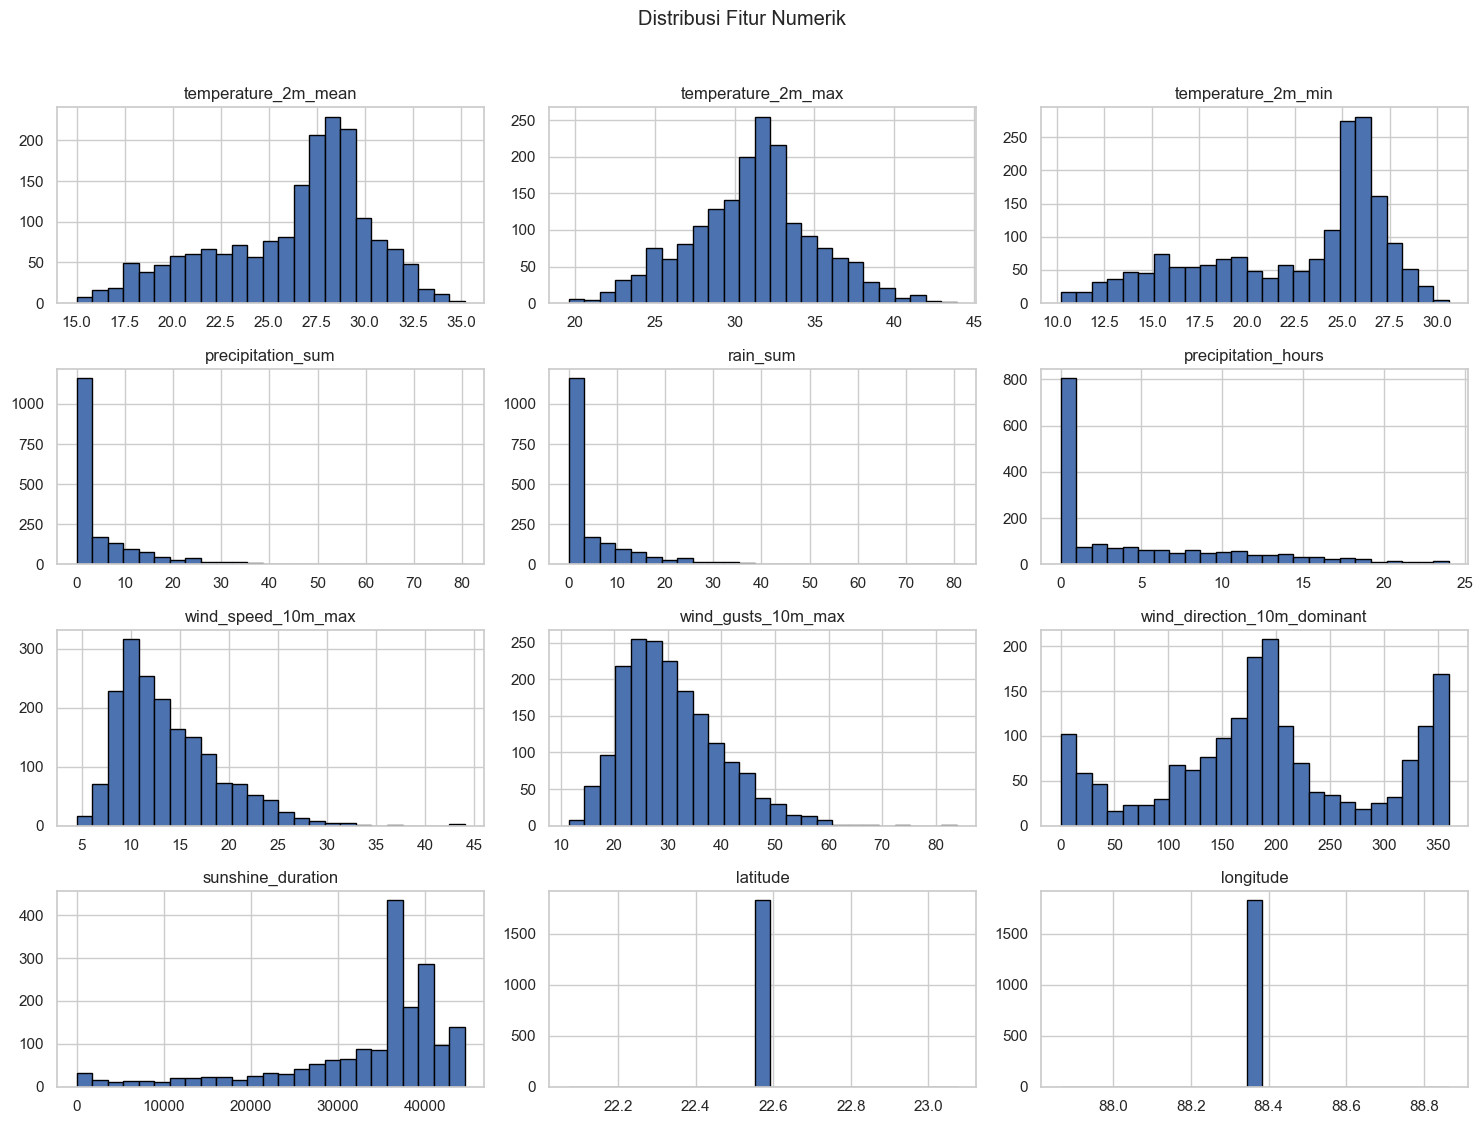

In [10]:
# Histogram fitur numerik
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_features_for_eda = [c for c in numeric_cols if c != "weather_code"]
df[numeric_features_for_eda].hist(figsize=(15, 11), bins=25, edgecolor="black")
plt.suptitle("Distribusi Fitur Numerik", y=1.02)
plt.tight_layout()
plt.show()


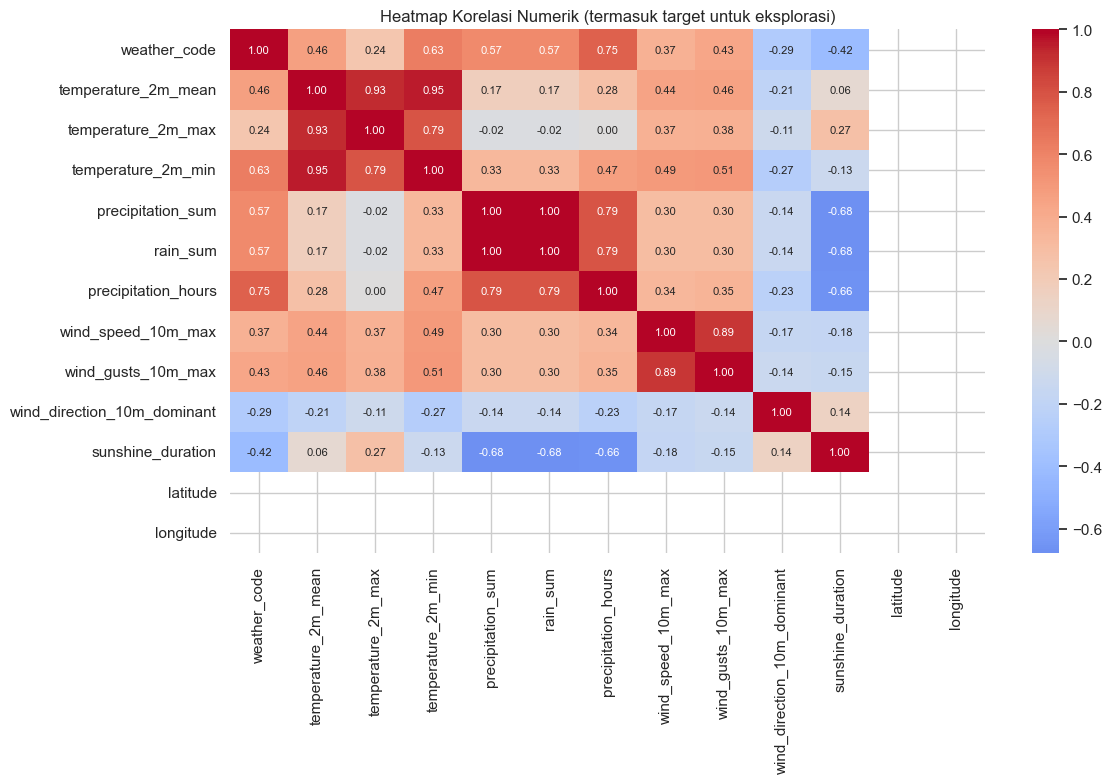

In [11]:
# Heatmap korelasi fitur numerik
plt.figure(figsize=(12, 8))
corr = df[numeric_cols].corr(numeric_only=True)
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title("Heatmap Korelasi Numerik (termasuk target untuk eksplorasi)")
plt.tight_layout()
plt.show()


<H2>4. Pra-pemrosesan Data dan Train-Test Split</H2>

In [12]:
# Kolom waktu matahari terbit/terbenam dan city bersifat teks.
# latitude/longitude konstan untuk satu kota sehingga tidak informatif; kolom waktu
# tidak digunakan sebagai fitur mentah. Target adalah weather_code.
TARGET = "weather_code"
drop_cols = [TARGET, "time", "sunrise", "sunset", "city", "latitude", "longitude"]
X = df.drop(columns=[c for c in drop_cols if c in df.columns]).copy()
y = df[TARGET].astype(int).copy()

# Pastikan fitur bersifat numerik dan nilai tak hingga ditangani
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

print("Fitur yang digunakan:", X.columns.tolist())
print("Jumlah fitur:", X.shape[1])
print("Kelas target:", sorted(y.unique()))
display(X.head())


Fitur yang digunakan: ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunshine_duration']
Jumlah fitur: 10
Kelas target: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(51), np.int64(53), np.int64(55), np.int64(61), np.int64(63), np.int64(65)]


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration
0,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,20837.76
1,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,21439.24
2,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,12291.52
3,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,29486.65
4,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,41145.46


In [13]:
# Split stratified agar proporsi kelas relatif terjaga.
# Imputer dipasang hanya pada data latih untuk menghindari data leakage.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)

print("Data latih:", X_train_imp.shape)
print("Data uji  :", X_test_imp.shape)
print("\nProporsi kelas train:")
display(y_train.value_counts(normalize=True).sort_index().round(3).rename("proporsi").to_frame())
print("\nProporsi kelas test:")
display(y_test.value_counts(normalize=True).sort_index().round(3).rename("proporsi").to_frame())


Data latih: (1461, 10)
Data uji  : (366, 10)

Proporsi kelas train:


,proporsi
weather_code,
0,0.125
1,0.051
2,0.042
3,0.222
51,0.092
53,0.059
55,0.022
61,0.079
63,0.229



Proporsi kelas test:


,proporsi
weather_code,
0,0.126
1,0.052
2,0.044
3,0.221
51,0.090
53,0.060
55,0.022
61,0.079
63,0.230


<H2>5. Membangun dan Melatih Model XGBoost Classifier</H2>

In [14]:
# Label kelas dipetakan ke indeks 0..n_classes-1 agar kompatibel lintas versi XGBoost.
class_labels = sorted(y.unique())
label_to_idx = {label: idx for idx, label in enumerate(class_labels)}
idx_to_label = {idx: label for label, idx in label_to_idx.items()}
y_train_enc = y_train.map(label_to_idx)
y_test_enc = y_test.map(label_to_idx)
n_classes = len(class_labels)

model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    objective="multi:softprob" if n_classes > 2 else "binary:logistic",
    num_class=n_classes if n_classes > 2 else None,
    eval_metric="mlogloss" if n_classes > 2 else "logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
model.fit(X_train_imp, y_train_enc)
y_pred_enc = model.predict(X_test_imp).astype(int)
y_proba = model.predict_proba(X_test_imp)
y_pred = pd.Series([idx_to_label[i] for i in y_pred_enc], index=y_test.index, name="prediksi")

print("Pelatihan model selesai.")


Pelatihan model selesai.


<h2>6. Evaluasi Model</h2>

In [15]:
accuracy = accuracy_score(y_test_enc, y_pred_enc)
precision = precision_score(y_test_enc, y_pred_enc, average="weighted", zero_division=0)
recall = recall_score(y_test_enc, y_pred_enc, average="weighted", zero_division=0)
f1 = f1_score(y_test_enc, y_pred_enc, average="weighted", zero_division=0)

# ROC-AUC multiclass dihitung dengan skema One-vs-Rest jika memungkinkan.
try:
    y_test_bin = label_binarize(y_test_enc, classes=list(range(n_classes)))
    roc_auc = roc_auc_score(y_test_bin, y_proba, multi_class="ovr", average="weighted")
except Exception as e:
    roc_auc = np.nan
    print("ROC-AUC tidak dapat dihitung:", e)

metrics_df = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision (weighted)", "Recall (weighted)", "F1-score (weighted)", "ROC-AUC (weighted OvR)"],
    "Nilai": [accuracy, precision, recall, f1, roc_auc]
})
display(metrics_df.style.format({"Nilai": "{:.4f}"}))
print("\nClassification report:")
print(classification_report(y_test_enc, y_pred_enc, labels=list(range(n_classes)),
                            target_names=[str(c) for c in class_labels], zero_division=0))


,Metrik,Nilai
0,Accuracy,0.6448
1,Precision (weighted),0.6265
2,Recall (weighted),0.6448
3,F1-score (weighted),0.6195
4,ROC-AUC (weighted OvR),0.9351



Classification report:
              precision    recall  f1-score   support

           0       0.48      0.63      0.55        46
           1       0.20      0.05      0.08        19
           2       0.50      0.06      0.11        16
           3       0.60      0.70      0.65        81
          51       0.97      0.85      0.90        33
          53       0.68      0.86      0.76        22
          55       0.33      0.12      0.18         8
          61       0.56      0.52      0.54        29
          63       0.73      0.85      0.78        84
          65       0.70      0.50      0.58        28

    accuracy                           0.64       366
   macro avg       0.57      0.51      0.51       366
weighted avg       0.63      0.64      0.62       366



<h2>7. Confusion Matrix</h2>

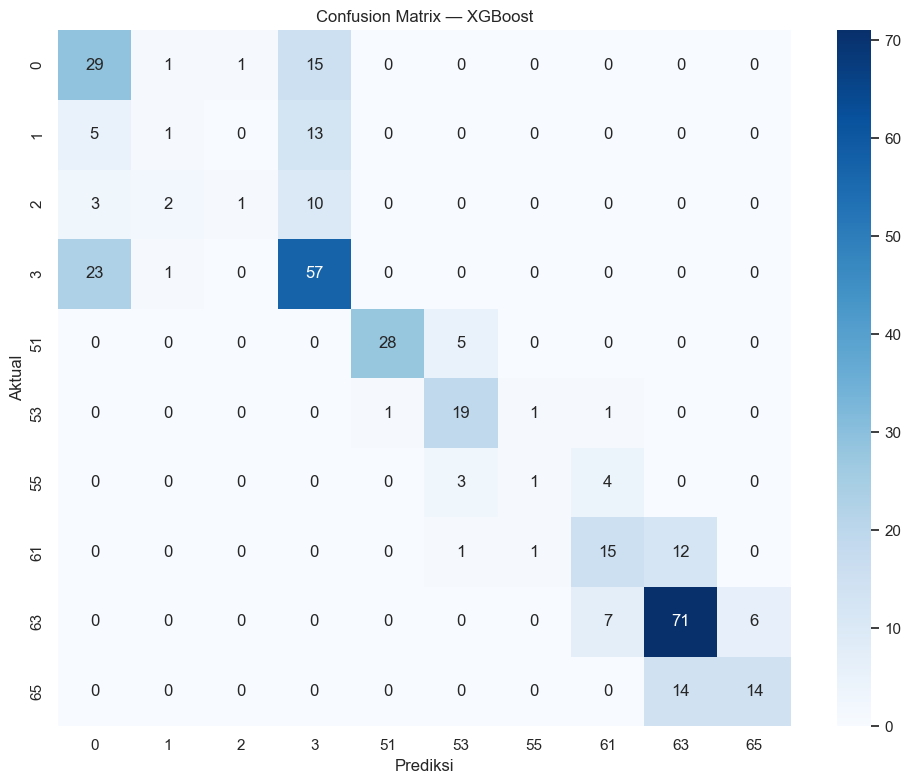

In [16]:
cm = confusion_matrix(y_test_enc, y_pred_enc, labels=list(range(n_classes)))
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_labels, yticklabels=class_labels)
plt.title("Confusion Matrix — XGBoost")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()


<h2>8. ROC Curve (Multiclass One-vs-Rest)</h2>

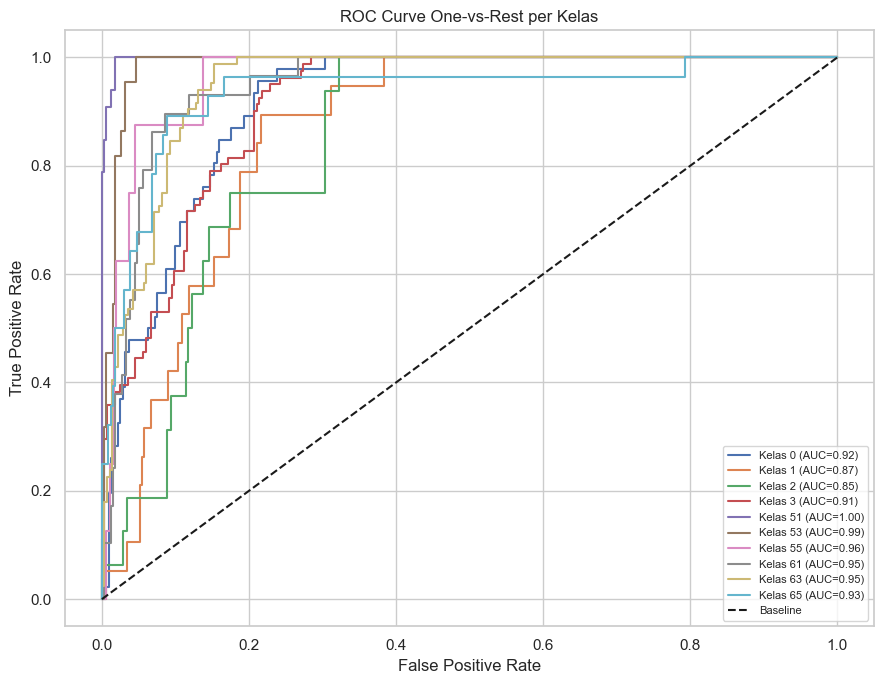

In [17]:
# ROC curve untuk tiap kelas, menggunakan pendekatan One-vs-Rest
y_test_bin = label_binarize(y_test_enc, classes=list(range(n_classes)))
plt.figure(figsize=(9, 7))
plotted = 0
for i, label in enumerate(class_labels):
    # ROC memerlukan contoh positif dan negatif di data uji
    if len(np.unique(y_test_bin[:, i])) < 2:
        continue
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    class_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"Kelas {label} (AUC={class_auc:.2f})")
    plotted += 1
plt.plot([0,  1], [0, 1], "k--", label="Baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve One-vs-Rest per Kelas")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()
if plotted == 0:
    print("ROC curve tidak dapat dibuat karena kelas pada data uji tidak memiliki variasi yang cukup.")


<h2>9. Feature Importance</h2>

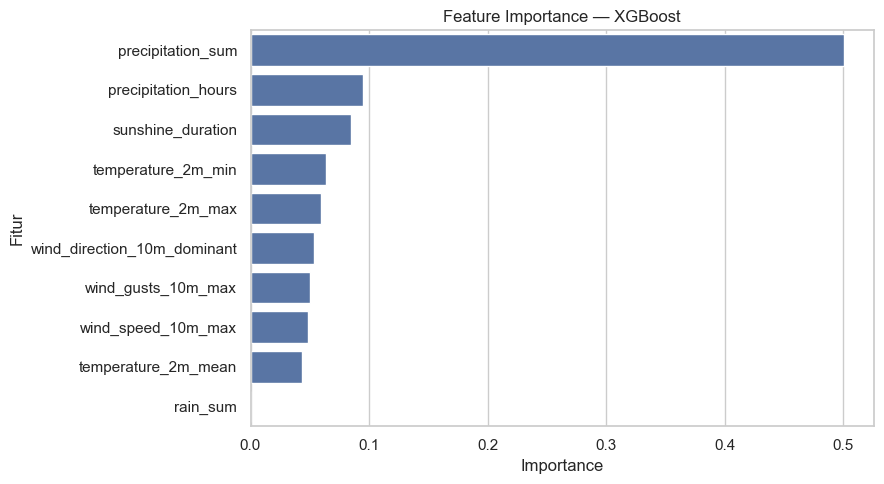

,importance
precipitation_sum,0.501080
precipitation_hours,0.095274
sunshine_duration,0.084799
temperature_2m_min,0.063358
temperature_2m_max,0.059861
wind_direction_10m_dominant,0.053397
wind_gusts_10m_max,0.050569
wind_speed_10m_max,0.048281
temperature_2m_mean,0.043383
rain_sum,0.000000


In [18]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(9, 5))
sns.barplot(x=importance.values, y=importance.index)
plt.title("Feature Importance — XGBoost")
plt.xlabel("Importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()
display(importance.rename("importance").to_frame())

<h2>10. Contoh Prediksi Manual</h2>

In [19]:
# Contoh menggunakan satu baris data uji; ganti nilai dengan pengukuran yang diinginkan.
sample = X_test_imp.iloc[[0]].copy()
pred_idx = int(model.predict(sample)[0])
pred_label = idx_to_label[pred_idx]
print("Input contoh:")
display(sample)
print("Prediksi weather_code:", pred_label)
print("Kode aktual:", int(y_test.iloc[0]))

Input contoh:


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration
1322,25.2,31.2,20.6,0.0,0.0,0.0,9.7,28.4,236.0,35839.9


Prediksi weather_code: 3
Kode aktual: 3


<h2>11. Simpan Model dan Komponen Preprocessing</h2>

In [20]:
import pickle

artifact = {
    "model": model,
    "imputer": imputer,
    "feature_columns": X.columns.tolist(),
    "class_labels": class_labels,
    "label_to_idx": label_to_idx,
    "idx_to_label": idx_to_label,
    "target": TARGET
}
with open("xgboost_weather_model.xls", "wb") as f:
    pickle.dump(artifact, f)

print("Artefak tersimpan: xgboost_weather_model.xls")


Artefak tersimpan: xgboost_weather_model.xls
